## Albedo Analysis
Assess how changes in albedo configuration affect model output.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

In [2]:
# Load the CSV data
df = pd.read_csv('../combined_results.csv')
df.head()

,site,latitude,longitude,output_years,bias_s00000000_ghec,rmse_s00000000_ghec,model_snow_days_s00000000_ghec,snotel_snow_days,mean_snotel_swe,var_snotel_swe,bias_s01011010_gbc,rmse_s01011010_gbc,model_snow_days_s01011010_gbc,bias_s01011010_ghec,rmse_s01011010_ghec,model_snow_days_s01011010_ghec,bias_s01011010_ghelaps,rmse_s01011010_ghelaps,model_snow_days_s01011010_ghelaps
0,Forestdale Creek,38.68,-119.96,16.0,-95.3,168.5,2909,3065,277.6,150622.6,7.2,63.5,3053,131.3,251.7,3678,55.8,106.6,3152
1,Horse Meadow,38.84,-119.89,11.2,-22.0,66.2,1627,1704,127.6,38347.5,-8.3,49.7,1601,49.2,110.3,1984,19.7,64.6,1723
2,Burnside Lake,38.72,-119.89,16.0,-7.2,89.5,3124,3055,196.3,83372.0,34.3,75.5,3081,133.7,254.1,3760,78.0,150.9,3269
3,Summit Meadow,38.40,-119.54,9.2,-9.4,67.5,1186,1153,103.5,25719.7,5.7,31.2,1176,67.9,140.2,1468,38.3,84.2,1312
4,Carson Pass,38.69,-120.00,14.0,-67.7,124.9,2500,2705,233.7,107471.6,-12.9,56.2,2585,87.3,205.2,3138,28.2,84.4,2719


In [3]:
# Remove sites where 'output_years' < 5
df = df[df['output_years'] >= 5]

### Normalized Bias Calculation
Normalize bias by dividing by the mean SWE at each site.

In [4]:
# Create a dataframe for bias
bias_df = df[['site', 'latitude', 'longitude', 'mean_snotel_swe', 'var_snotel_swe', 'bias_s00000000_ghec', 'bias_s01011010_ghec', 'bias_s01011010_ghelaps', 'bias_s01011010_gbc']].copy()

In [5]:
bias_df['nbias_s00000000_ghec'] = bias_df['bias_s00000000_ghec'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghec'] = bias_df['bias_s01011010_ghec'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghelaps'] = bias_df['bias_s01011010_ghelaps'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_gbc'] = bias_df['bias_s01011010_gbc'] / bias_df['mean_snotel_swe']

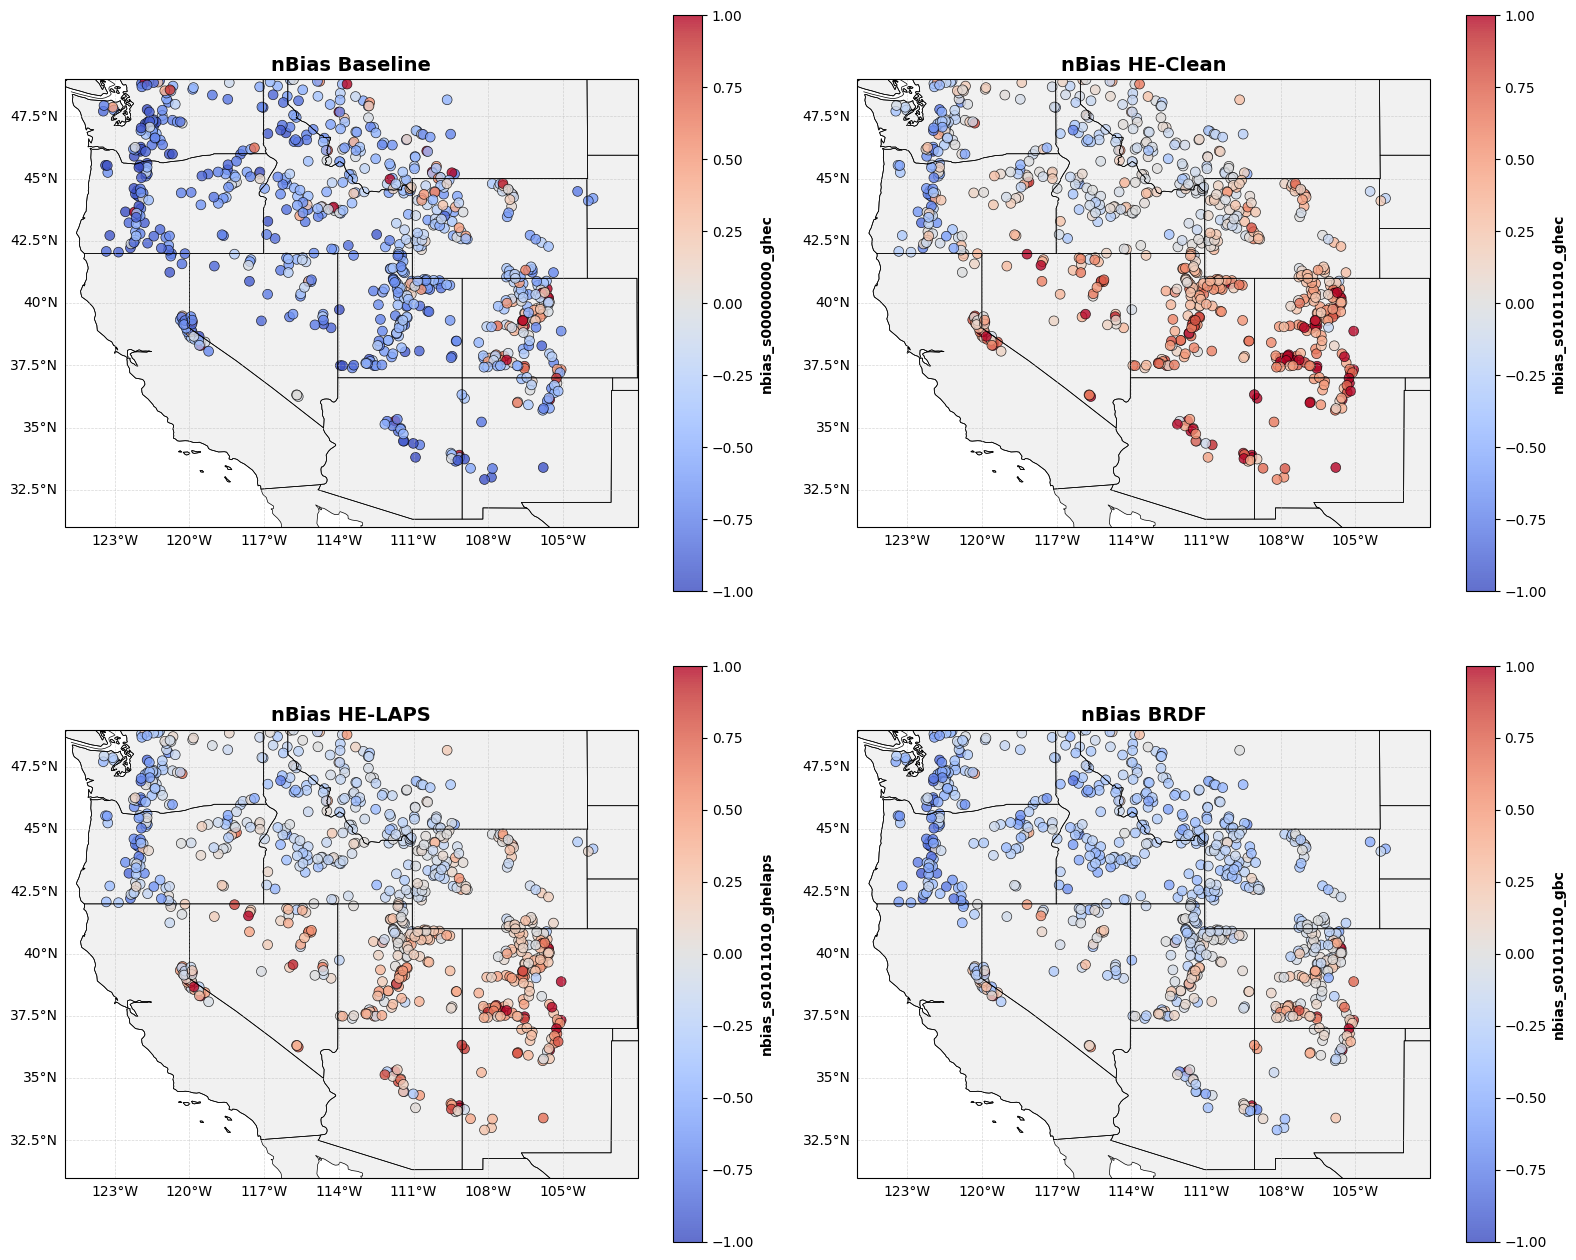

Total data points: 765

Value ranges:
nbias_s00000000_ghec: -1.00 to 3.76
nbias_s01011010_ghec: -0.96 to 37.46
nbias_s01011010_ghelaps: -0.96 to 3.10
nbias_s01011010_gbc: -0.97 to 2.01

Shared colormap range: -1 to 1 (centered on 0)


In [6]:
# Plot normalized bias
# Create figure with 2x2 grid of subplots for normalized bias
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']
titles = ['nBias Baseline', 'nBias HE-Clean', 'nBias HE-LAPS', 'nBias BRDF']

# Set color scale limits centered on 0
vmin = -1
vmax = 1

# Create four subplots in 2x2 grid
for pos, (column, title) in enumerate(zip(columns, titles), 1):
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Plot the data points
    scatter = ax.scatter(bias_df['longitude'], bias_df['latitude'],
                         c=bias_df[column],
                         s=50,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(bias_df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {bias_df[column].min():.2f} to {bias_df[column].max():.2f}")
print(f"\nShared colormap range: {vmin} to {vmax} (centered on 0)")

### Snow Days

In [7]:
# Create a dataframe for snow days
snow_days_df = df[['site',
                   'latitude',
                   'longitude',
                   'output_years',
                   'mean_snotel_swe',
                   'var_snotel_swe',
                   'snotel_snow_days',
                   'model_snow_days_s00000000_ghec',
                   'model_snow_days_s01011010_ghec',
                   'model_snow_days_s01011010_ghelaps',
                   'model_snow_days_s01011010_gbc']].copy()

In [8]:
# Calculate various differences normalized by number of years
snow_days_df['dsnow_days_s00000000_ghec'] = (snow_days_df['model_snow_days_s00000000_ghec'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']
snow_days_df['dsnow_days_s01011010_ghec'] = (snow_days_df['model_snow_days_s01011010_ghec'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']
snow_days_df['dsnow_days_s01011010_ghelaps'] = (snow_days_df['model_snow_days_s01011010_ghelaps'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']
snow_days_df['dsnow_days_s01011010_gbc'] = (snow_days_df['model_snow_days_s01011010_gbc'] - snow_days_df['snotel_snow_days']) / snow_days_df['output_years']

snow_days_df['dsnow_days_hec_helaps'] = (snow_days_df['model_snow_days_s01011010_ghec'] - snow_days_df['model_snow_days_s01011010_ghelaps']) / snow_days_df['output_years']

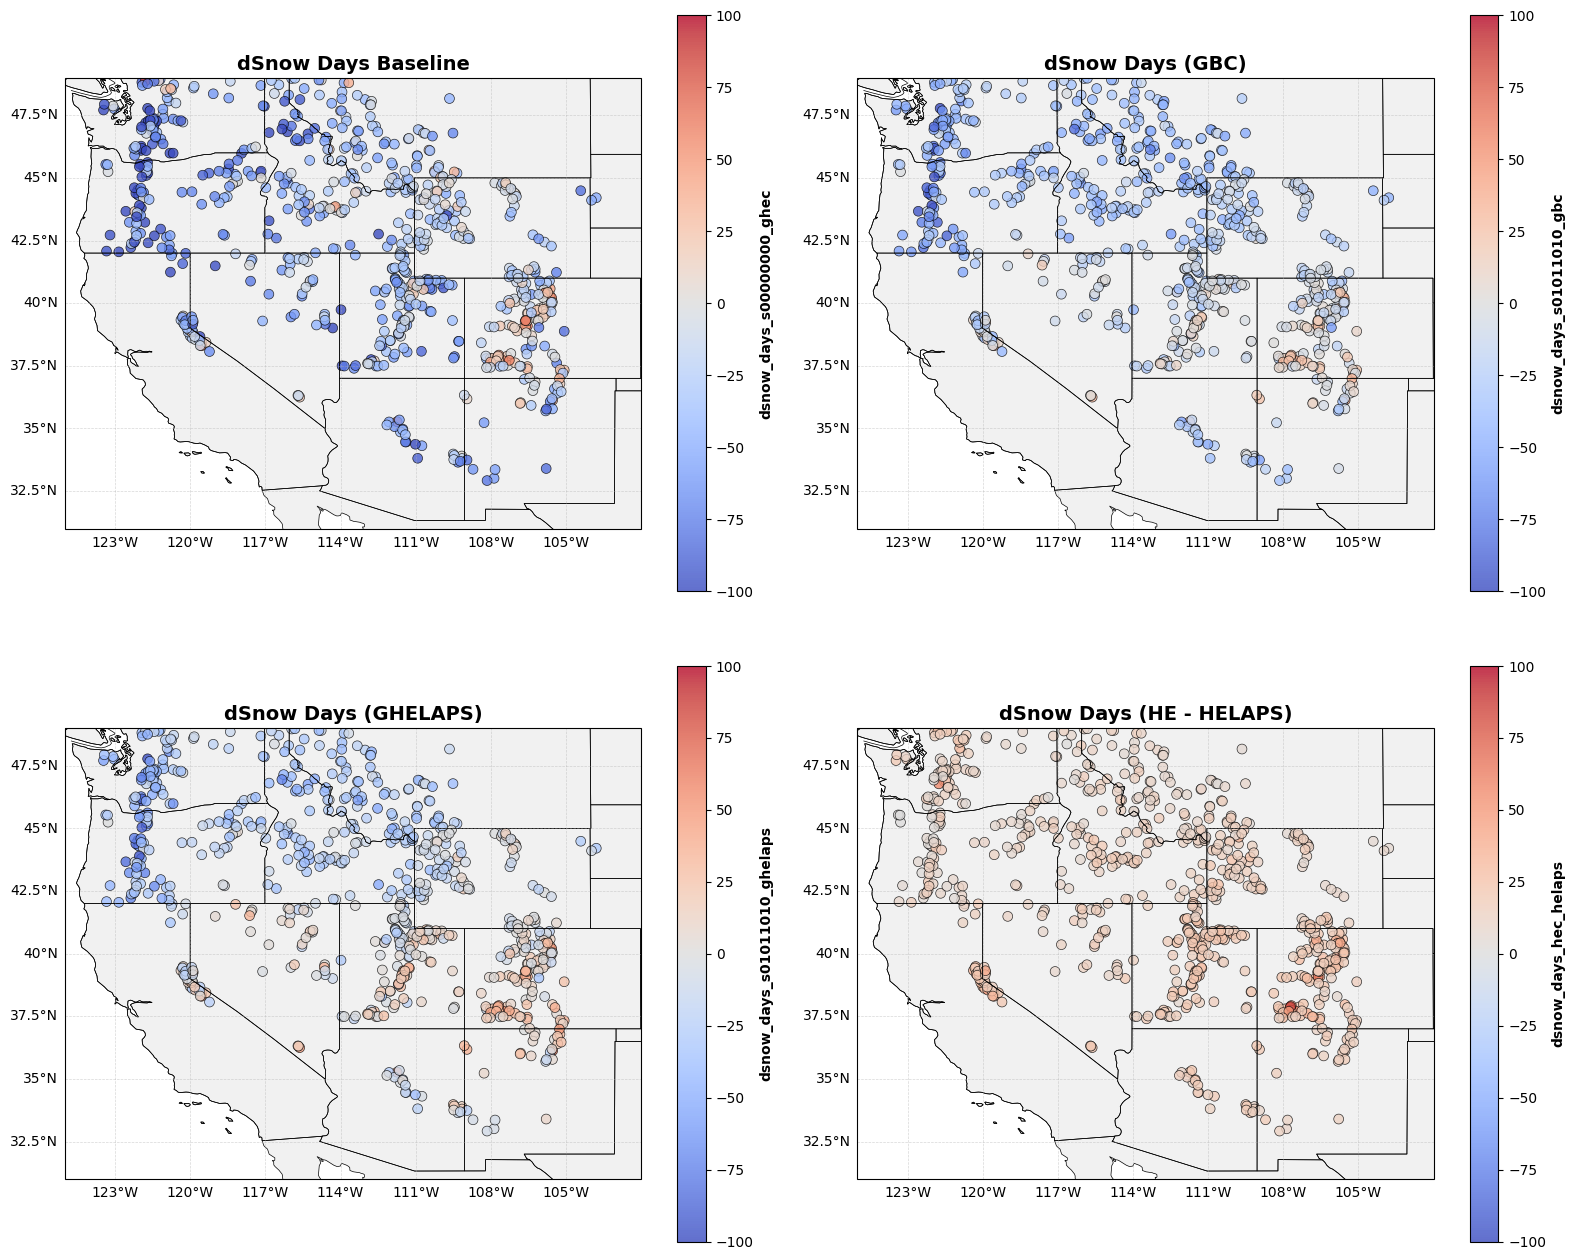

Total data points: 765

Value ranges:
dsnow_days_s00000000_ghec: -210.80 to 85.54
dsnow_days_s01011010_gbc: -123.60 to 44.83
dsnow_days_s01011010_ghelaps: -114.60 to 63.77
dsnow_days_hec_helaps: 0.00 to 85.97

Shared colormap range: -100 to 100 (centered on 0)


In [9]:
# Create figure with 2x2 grid of subplots for normalized bias
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['dsnow_days_s00000000_ghec', 'dsnow_days_s01011010_gbc', 'dsnow_days_s01011010_ghelaps', 'dsnow_days_hec_helaps']
titles = ['dSnow Days Baseline', 'dSnow Days (GBC)', 'dSnow Days (GHELAPS)', 'dSnow Days (HE - HELAPS)']

# Set color scale limits centered on 0
vmin, vmax = (-100, 100)


# Create four subplots in 2x2 grid
for pos, (column, title) in enumerate(zip(columns, titles), 1):
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Plot the data points
    scatter = ax.scatter(snow_days_df['longitude'], snow_days_df['latitude'],
                         c=snow_days_df[column],
                         s=50,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(snow_days_df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {snow_days_df[column].min():.2f} to {snow_days_df[column].max():.2f}")
print(f"\nShared colormap range: {vmin} to {vmax} (centered on 0)")

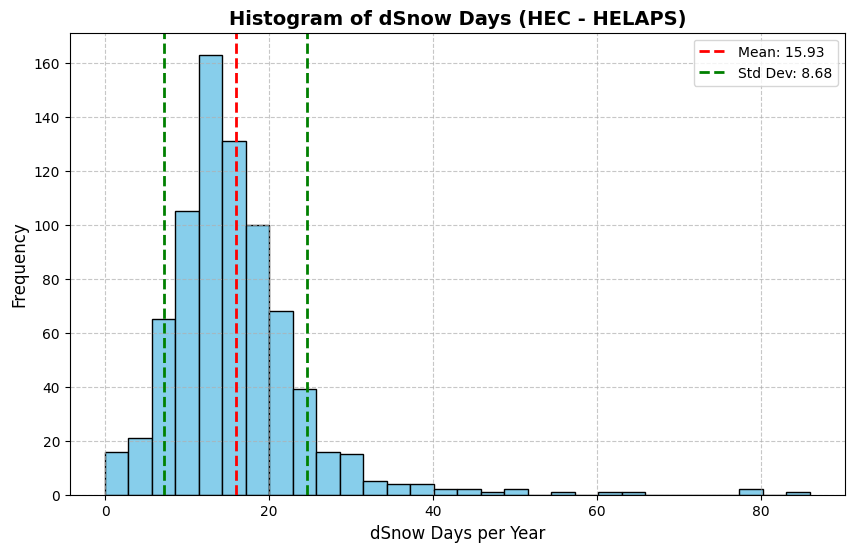

In [10]:
# Histogram of dsnow_days_hec_helaps
plt.figure(figsize=(10, 6))
plt.hist(snow_days_df['dsnow_days_hec_helaps'], bins=30, color='skyblue', edgecolor='black')
plt.title('Histogram of dSnow Days (HEC - HELAPS)', fontsize=14, fontweight='bold')
plt.xlabel('dSnow Days per Year', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Plot mean and stddev lines
mean_diff = snow_days_df['dsnow_days_hec_helaps'].mean()
stddev_diff = snow_days_df['dsnow_days_hec_helaps'].std()
plt.axvline(mean_diff, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_diff:.2f}')
plt.axvline(mean_diff + stddev_diff, color='green', linestyle='dashed', linewidth=2, label=f'Std Dev: {stddev_diff:.2f}')
plt.axvline(mean_diff - stddev_diff, color='green', linestyle='dashed', linewidth=2)
plt.legend()


### Elevational Comparison

In [11]:
# Load topography data
#SNOTEL_PATH = '/home/chriscox/Data/snotel/'
SNOTEL_PATH = 'C:/Users/clmbn/NMT_PhD/data/snotel/'
snotel_topo = pd.read_csv(SNOTEL_PATH + 'snotel_land_data.csv')
snotel_topo

,SNOTEL Name,SNOTEL Lat (),SNOTEL Lon (),points_x,ELEVATION,points_y,SLOPE,points_x.1,ASPECT,points_y.1,SKY_VIEW_FACTOR,points,TERRAIN_CONFIG
0,Annie Springs,42.87,-122.17,0,1917.0,0,4.0,0,187.0,0,1.00,0,0.00
1,Long Lake,58.19,-133.83,1,414.0,1,11.0,1,147.0,1,0.93,1,0.06
2,Mcneil Canyon,59.74,-151.25,2,327.0,2,6.0,2,165.0,2,0.99,2,0.00
3,Ute Creek,37.61,-105.37,3,3249.0,3,11.0,3,131.0,3,0.99,3,0.00
4,Lewis Peak,40.36,-116.86,4,2277.0,4,6.0,4,234.0,4,0.99,4,0.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
824,Moscow Mountain,46.81,-116.85,824,1279.0,824,6.0,824,72.0,824,1.00,824,-0.00
825,Beaver Pass,48.88,-121.26,825,1259.0,825,15.0,825,103.0,825,0.94,825,0.04
826,Bear River RS,40.89,-110.83,826,2615.0,826,3.0,826,276.0,826,1.00,826,0.00
827,Easy Pass,48.86,-121.44,827,1439.0,827,18.0,827,215.0,827,0.94,827,0.03


In [12]:
# Merge bias_df with snotel_topo on site name
# Need to match 'site' in bias_df with 'SNOTEL Name' in snotel_topo
merged_df = bias_df.merge(snotel_topo[['SNOTEL Name', 'ELEVATION']], 
                          left_on='site', right_on='SNOTEL Name', how='inner')

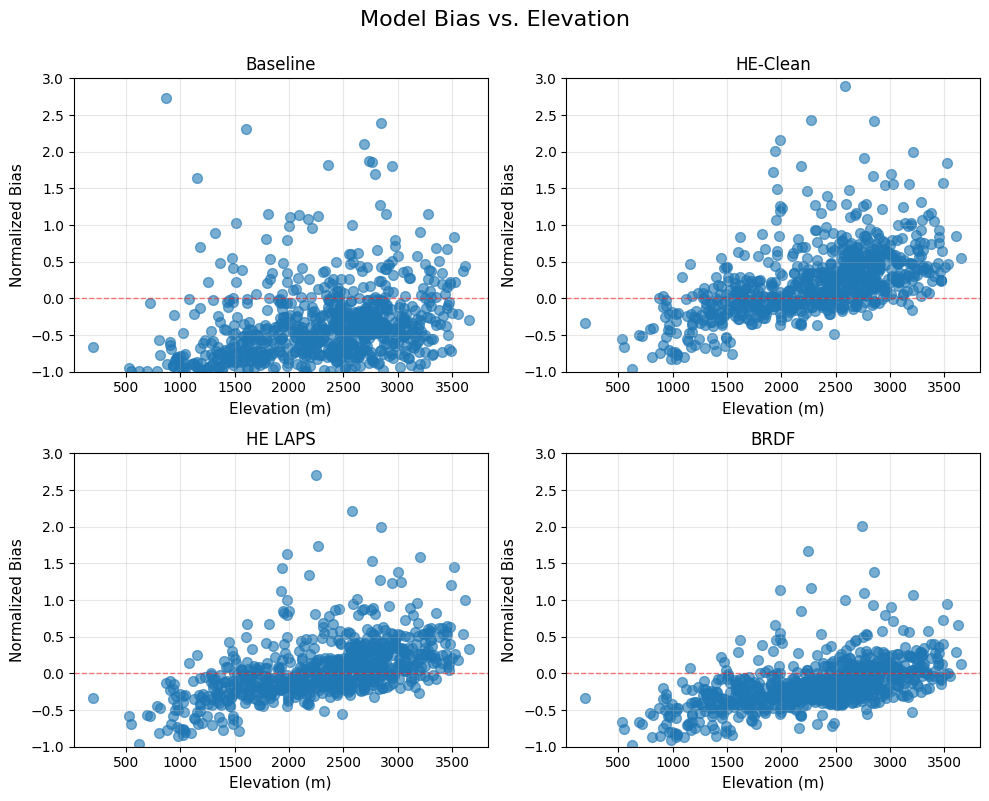

Number of sites plotted: 765


In [15]:
# Bias and Elevation
# Create 2x2 subplot figure
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
fig.suptitle('Model Bias vs. Elevation', fontsize=16, y=0.995)

# Flatten axes for easier iteration
axes = axes.flatten()

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec','nbias_s01011010_ghec','nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['Baseline','HE-Clean','HE LAPS', 'BRDF']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    ax = axes[idx]
    
    # Create scatter plot
    ax.scatter(merged_df['ELEVATION'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Elevation (m)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Set y-axis limits
    ax.set_ylim(-1, 3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Number of sites plotted: {len(merged_df)}")